In [1]:
import pandas as pd
import numpy as np
from scipy.sparse import hstack, csr_matrix

from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.naive_bayes import MultinomialNB

from sklearn.feature_selection import f_classif
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedGroupKFold, PredefinedSplit
from sklearn.metrics import classification_report, f1_score, accuracy_score

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [3]:
df = pd.read_csv(Path("/mnt/data/datasets/spotify_tracks/tracks.csv"))

## 1.1 Exploratory Data Analysis

### 1.1.1 Dataset Overview

In [5]:
df.head()

,Unnamed: 0,track_name,track_id,album_name,album_id,album_image,album_release_date,album_release_date_precision,artist_name,artist_id,popularity,duration_ms,explicit,preview_url,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
0,0,"Divenire: No. 9, Fly - Intouchables",5u5scm02d5wN6nWFKuqEUK,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,2,265653,False,https://p.scdn.co/mp3-preview/81f71ca4ea95503e...,ambient,0.990,0.184,0.03270,0.877,1,0.0996,-28.184,0,0.0366,168.133,3,0.0351,0,265.653,4.427550
1,1,Spiegel im Spiegel - Heaven,1wV4SNFEXWawsyjBCGwkiw,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,349120,False,https://p.scdn.co/mp3-preview/040ea9c848708316...,ambient,0.985,0.250,0.01480,0.971,5,0.0669,-30.646,1,0.0375,136.864,5,0.0394,0,349.120,5.818667
2,2,Truman Sleeps - The Trumanshow,4gYub3T80gNfU9F4Df98AR,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,1,128039,False,https://p.scdn.co/mp3-preview/e9a7cd955c89d480...,ambient,0.993,0.269,0.02110,0.883,5,0.1390,-24.620,0,0.0395,69.487,4,0.0411,0,128.039,2.133983
3,3,The Heart Askes Pleasure First - The Piano,6sXRgSAQsySTM7kH1pM07Y,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,190960,False,https://p.scdn.co/mp3-preview/9a33da62792f8277...,ambient,0.995,0.230,0.13800,0.885,4,0.1010,-19.591,0,0.0371,165.197,3,0.1710,0,190.960,3.182667
4,4,3 Gymnopédies: I. Lent et douloureux,7Eytd0e0mNFiSWIE132H76,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,4,338933,False,https://p.scdn.co/mp3-preview/d31979ca20bbd759...,ambient,0.995,0.611,0.00162,0.967,7,0.0817,-37.782,1,0.2860,134.237,3,0.5080,0,338.933,5.648883


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2112746 entries, 0 to 2112745
Data columns (total 30 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0   Unnamed: 0                    int64  
 1   track_name                    str    
 2   track_id                      str    
 3   album_name                    str    
 4   album_id                      str    
 5   album_image                   str    
 6   album_release_date            str    
 7   album_release_date_precision  str    
 8   artist_name                   str    
 9   artist_id                     str    
 10  popularity                    int64  
 11  duration_ms                   int64  
 12  explicit                      bool   
 13  preview_url                   str    
 14  genre                         str    
 15  acousticness                  float64
 16  danceability                  float64
 17  energy                        float64
 18  instrumentalness              flo

### 1.1.2 Dataset Quality

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.isnull().sum()

Unnamed: 0                           0
track_name                           6
track_id                             0
album_name                           6
album_id                             0
album_image                        491
album_release_date                   0
album_release_date_precision         0
artist_name                         17
artist_id                            0
popularity                           0
duration_ms                          0
explicit                             0
preview_url                     325237
genre                                0
acousticness                         0
danceability                         0
energy                               0
instrumentalness                     0
key                                  0
liveness                             0
loudness                             0
mode                                 0
speechiness                          0
tempo                                0
time_signature           

In [4]:
df = df.drop(columns=['Unnamed: 0', 'database_shard_id', 'preview_url', 'track_id', 'album_image', 'album_release_date', 'album_release_date_precision', 'artist_name', 'artist_id', 'duration_ms', 'duration_minutes'])

In [5]:
df = df.dropna()

In [6]:
df["explicit"] = df["explicit"].astype(int)

### 1.1.3 Feature Relationship and Distribution

In [9]:
df.describe()

,popularity,explicit,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,duration_seconds
count,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06
mean,1.377672e+01,4.922858e-02,3.921944e-01,5.285379e-01,5.833878e-01,2.188482e-01,5.248915e+00,2.245102e-01,-1.025286e+01,6.620699e-01,8.522004e-02,1.202604e+02,3.873687e+00,4.874519e-01,2.494331e+02
std,1.463674e+01,2.163450e-01,3.669645e-01,1.797403e-01,2.759472e-01,3.469544e-01,3.532850e+00,2.025182e-01,5.799943e+00,4.730047e-01,1.185055e-01,2.977376e+01,4.701898e-01,2.726175e-01,1.453019e+02
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.970000e-05,0.000000e+00,0.000000e+00,2.960000e-03,-5.810000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.860000e-01
25%,1.000000e+00,0.000000e+00,2.210000e-02,4.040000e-01,3.700000e-01,1.180000e-06,2.000000e+00,9.770000e-02,-1.290100e+01,0.000000e+00,3.570000e-02,9.711000e+01,4.000000e+00,2.560000e-01,1.795000e+02
50%,9.000000e+00,0.000000e+00,2.890000e-01,5.390000e-01,6.130000e-01,8.260000e-04,5.000000e+00,1.370000e-01,-8.900000e+00,1.000000e+00,4.720000e-02,1.199840e+02,4.000000e+00,4.840000e-01,2.268860e+02
75%,2.200000e+01,0.000000e+00,7.600000e-01,6.630000e-01,8.260000e-01,4.060000e-01,8.000000e+00,2.910000e-01,-6.117000e+00,1.000000e+00,7.850000e-02,1.385590e+02,4.000000e+00,7.150000e-01,2.878800e+02
max,1.000000e+02,1.000000e+00,9.960000e-01,9.950000e-01,1.000000e+00,1.000000e+00,1.100000e+01,1.000000e+00,6.172000e+00,1.000000e+00,9.690000e-01,2.499930e+02,5.000000e+00,1.000000e+00,7.200006e+03


In [10]:
print(df['genre'].value_counts().to_string())

genre
classical            48143
blues                45752
indian               43616
german               43002
french               40832
country              38847
british              38476
alt-rock             37065
disco                34808
brazil               34482
opera                34056
turkish              33997
pop-film             32268
dance                32059
jazz                 31340
ambient              30898
gospel               30422
latin                30368
spanish              30298
folk                 29167
funk                 28505
guitar               27087
bluegrass            27073
k-pop                26456
j-pop                26114
swedish              25838
dub                  25670
acoustic             25669
children             25597
new-age              25164
mpb                  25108
anime                24623
black-metal          23511
dancehall            23477
forro                23266
cantopop             23036
death-metal          2

In [50]:
df_numerical = df.select_dtypes(include='number')

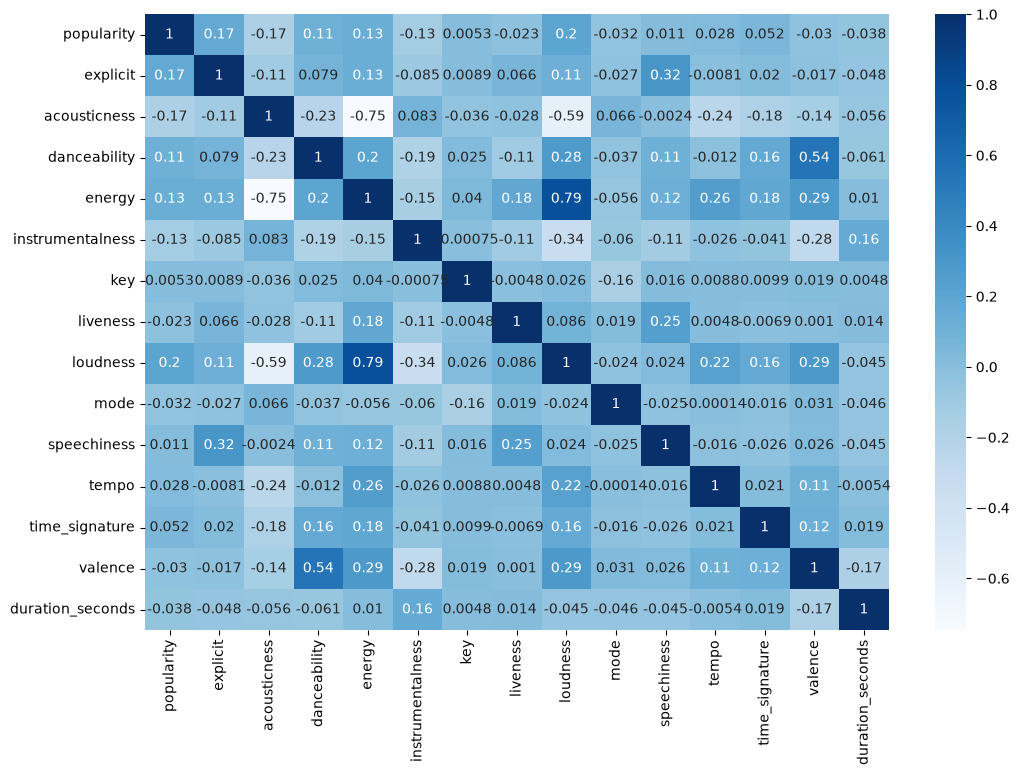

In [8]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df_numerical.corr(),
    annot=True,
    cmap='Blues'
)

plt.show()

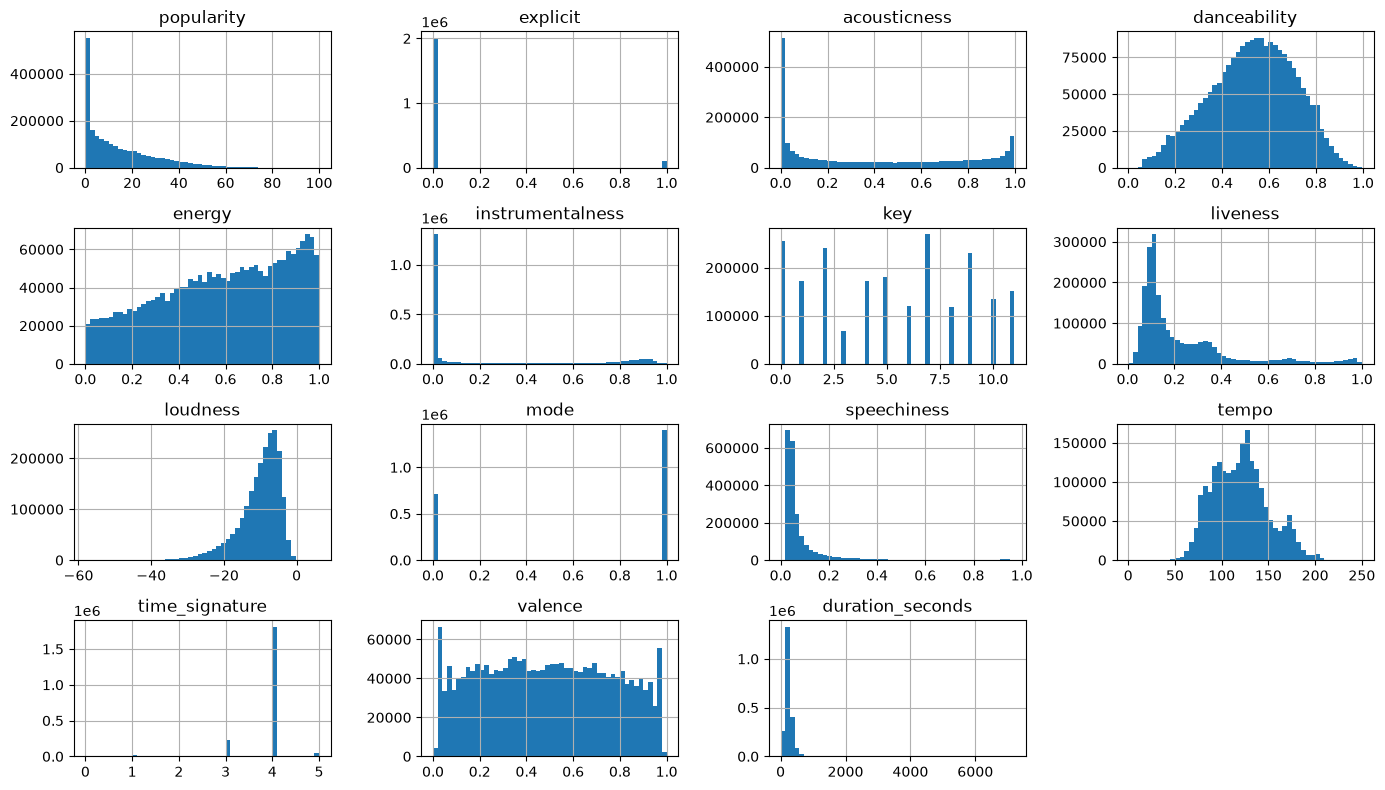

In [8]:
df_numerical.hist(bins=50, figsize=(14, 8))

plt.tight_layout()
plt.show()

### 1.1.4 Feature Distribution and Class Imbalance

The histograms above show that some continous numerical features have asymmetric distributions. Skewness describes the asymmetry of a data distribution around its mean.
This could negatively impact the performance of models that assume normally distributed data or are sensitive to the variance of input features, such as linear regression, principal component analysis (PCA), and support vector machines (SVMs).
- **Positive skewness (right-skewed):** the distribution has a longer tail towards higher values.
- **Negative skewness (left-skewed):** the distribution has a longer tail towards lower values.

Based on the histograms, the following features appear to be positively skewed:
- `duration_seconds`
- `liveness`
- `instrumentalness`
- `popularity`

The following features appear to be negatively skewed:
- `energy`
- `loudness`

The skewness of `acousticness` is less clear from the histogram alone and will be investigated further in the next step.

In [13]:
df_numerical.skew()

popularity          1.214319
explicit            4.166496
acousticness        0.423765
danceability       -0.225347
energy             -0.369376
instrumentalness    1.123735
key                -0.003725
liveness            1.953287
loudness           -1.436084
mode               -0.656765
speechiness         4.721345
tempo               0.344123
time_signature     -3.153546
valence             0.054440
duration_seconds    8.817976
dtype: float64

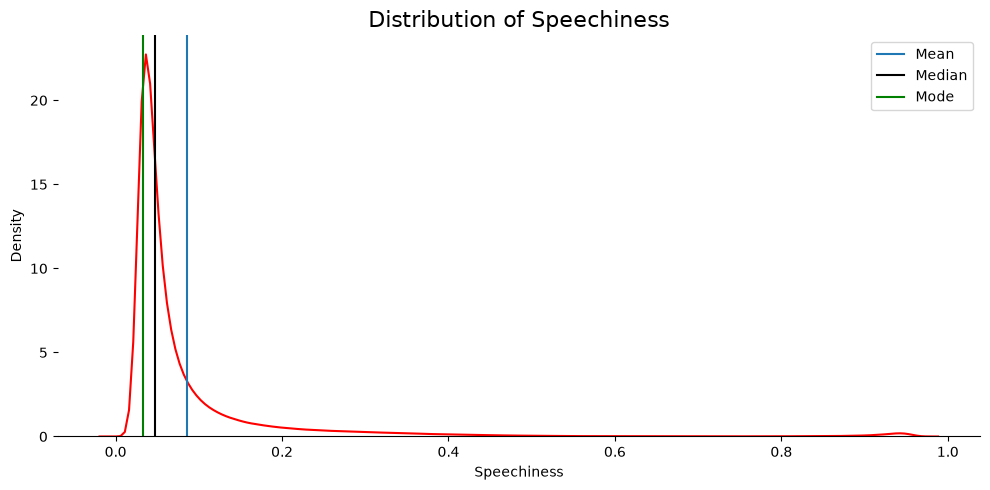

In [16]:
# Find the mean, median, mode
mean_value = df["speechiness"].mean()
median_value = df["speechiness"].median()
mode_value = df["speechiness"].mode().iloc[0]

plt.figure(figsize=(10, 5))
sns.kdeplot(x=df['speechiness'], color="red")

# Add vertical lines at the position of mean, median, mode
plt.axvline(mean_value, label="Mean")
plt.axvline(median_value, color="black", label="Median")
plt.axvline(mode_value, color="green", label="Mode")

plt.title("Distribution of Speechiness", fontsize=16)
plt.xlabel("Speechiness")
plt.ylabel("Density")
sns.despine(top=True, right=True, left=True)
plt.legend()
plt.tight_layout()
plt.show()


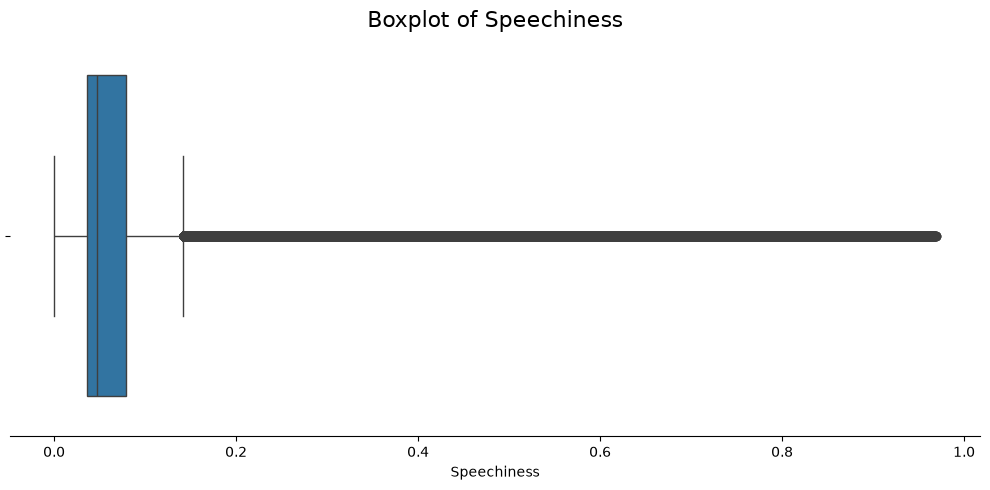

In [17]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["speechiness"])

plt.title("Boxplot of Speechiness", fontsize=16)
plt.xlabel("Speechiness")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

The KDE plot (*continous*) and boxplot of speechiness confirm its positive skewness of 4.77, as we saw on the histogram (*bins*). Most observations are concentrated at **lower values**, with a **long tail** extending towards higher values, on the right side of the peak.

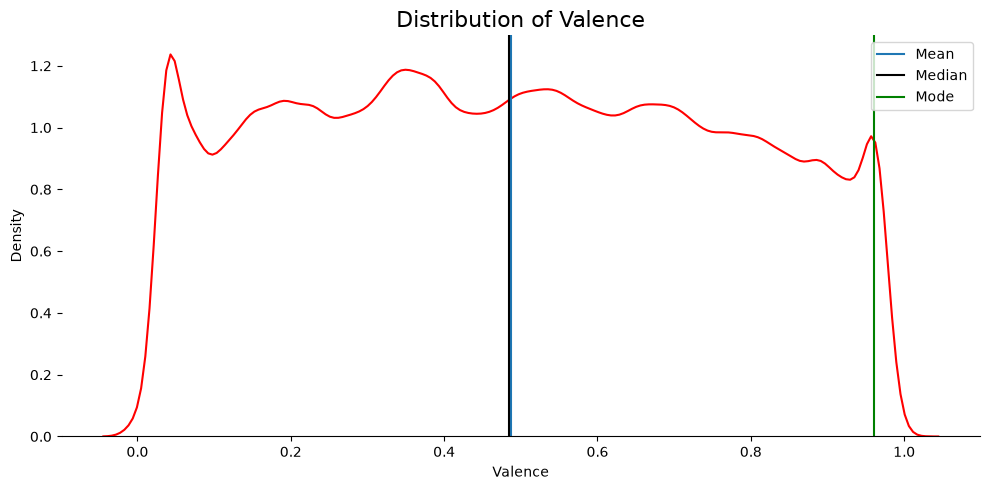

In [19]:
# Find the mean, median, mode
mean_value = df["valence"].mean()
median_value = df["valence"].median()
mode_value = df["valence"].mode().iloc[0]

plt.figure(figsize=(10, 5))
sns.kdeplot(x=df['valence'], color="red")

# Add vertical lines at the position of mean, median, mode
plt.axvline(mean_value, label="Mean")
plt.axvline(median_value, color="black", label="Median")
plt.axvline(mode_value, color="green", label="Mode")

plt.title("Distribution of Valence", fontsize=16)
plt.xlabel("Valence")
plt.ylabel("Density")
sns.despine(top=True, right=True, left=True)
plt.legend()
plt.tight_layout()
plt.show()


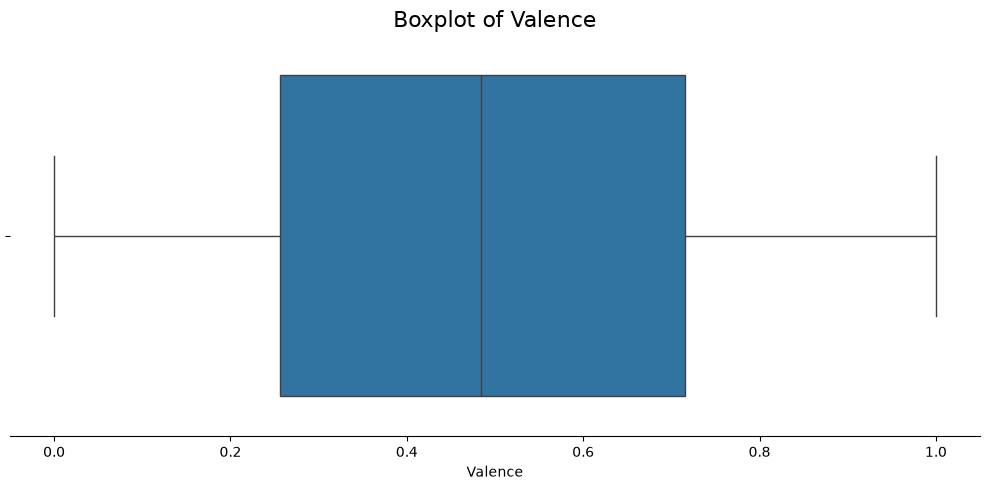

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["valence"])

plt.title("Boxplot of Valence", fontsize=16)
plt.xlabel("Valence")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

The KDE plot and boxplot of valence show a relatively symmetric distribution, consistent with its near-zero skewness of 0.05, as observed in the histogram. The mean and median are close together, and the distribution does not show a pronounced tail towards either lower or higher values.

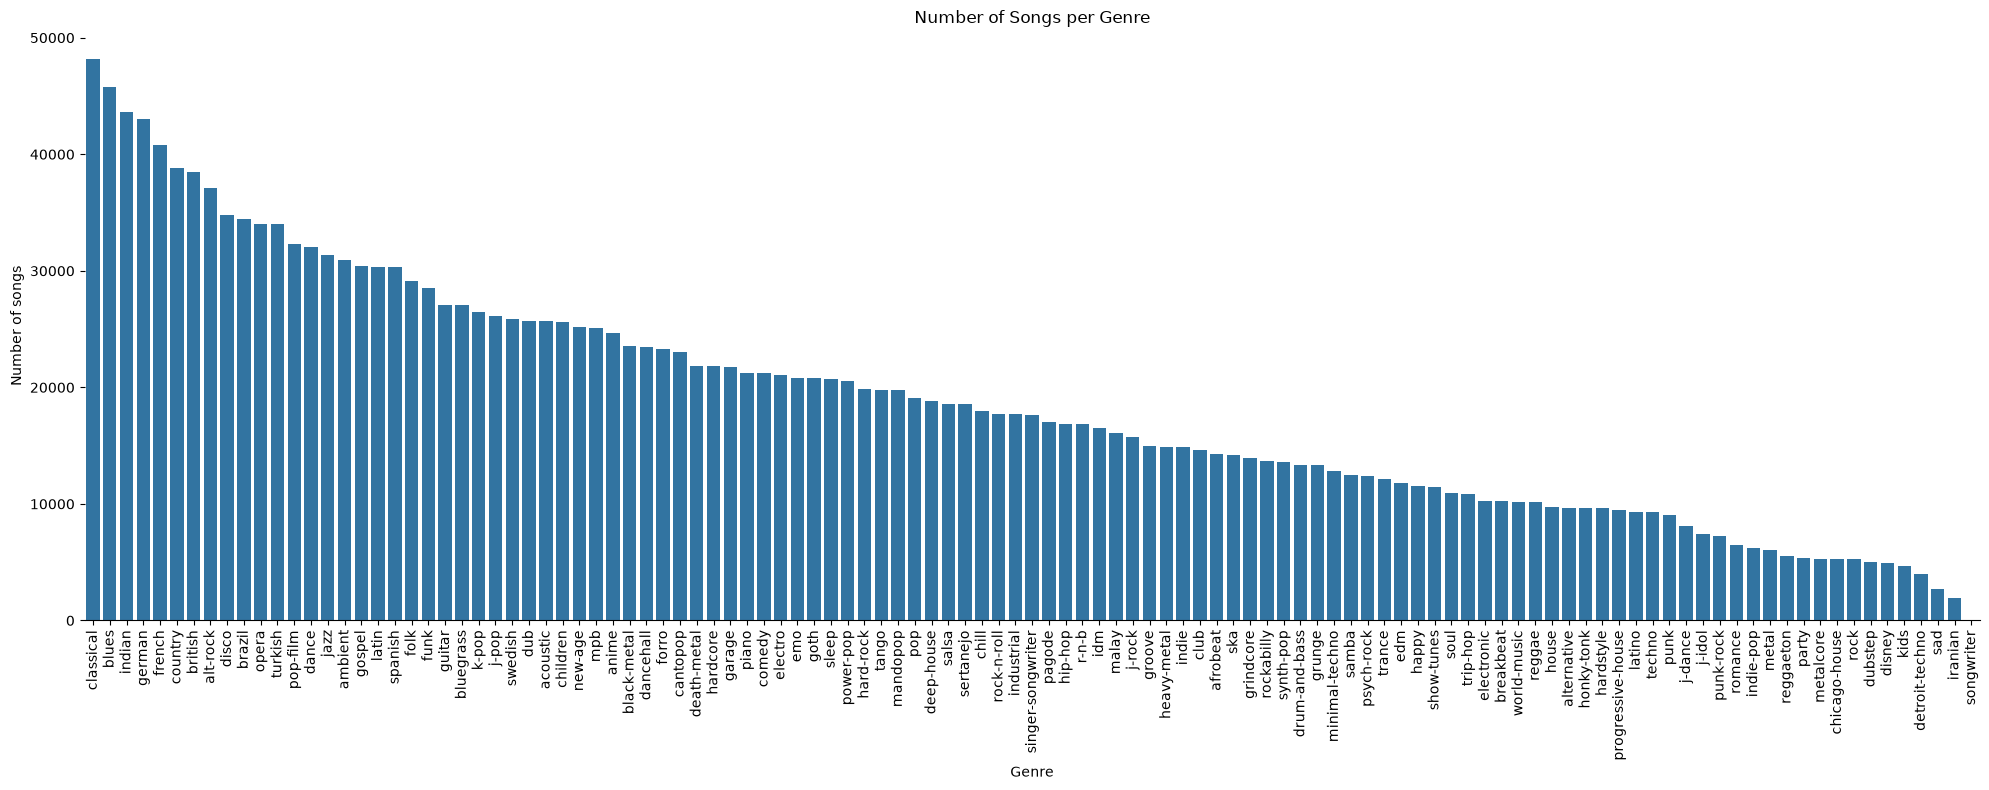

In [17]:
plt.figure(figsize=(20, 8))

genre_order = df["genre"].value_counts().index

ax = sns.countplot(
    data=df,
    x="genre",
    order=genre_order
)

plt.xticks(rotation=90)
plt.xlabel("Genre")
plt.ylabel("Number of songs")
plt.title("Number of Songs per Genre")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

The countplot shows the distribution of tracks across genres, ordered from most frequent to least frequent. The number of tracks varies considerably between genres: classical is the most represented genre, with 48,143 tracks, whereas songwriter has only 66 tracks. This indicates a substantial class imbalance, which may cause the classification model to perform better on well-represented genres than on underrepresented ones.

### 1.1.5 Correlation and Multicollinearity

In [7]:
le = LabelEncoder()

In [8]:
df['genre'] = le.fit_transform(df["genre"])

In the next step we calculate the **ANOVA F-statistic**, as our input variables are numerical and output variables are non-ordinal categorical. This informs us what features correlate highly with the output variable, genre.

For more information, see [How to Choose a Feature Selection Method For Machine Learning](https://machinelearningmastery.com/feature-selection-with-real-and-categorical-data/).

In [20]:
f_statistic, _ = f_classif(df_numerical, df['genre'])

anova_df = pd.DataFrame({
    "feature": df_numerical.columns,
    "F-value": f_statistic
}).sort_values("F-value", ascending=False)

anova_df

,feature,F-value
2,acousticness,15341.086211
4,energy,12723.796624
10,speechiness,12482.232343
8,loudness,11720.552705
3,danceability,9762.619755
5,instrumentalness,9546.905802
13,valence,7157.059485
0,popularity,5811.233903
1,explicit,4485.733723
14,duration_seconds,2018.075839


The highest F-values observed are `acousticness`, `speechiness` and `energy`.

We calculate the **Variance Inflation Factor** (VIF) to detect multicollinearity between the numerical input variables. This indicates whether some features contain overlapping information, and could therefore mislead the model.

In [21]:
vif_df = pd.DataFrame({
    "feature": df_numerical.columns,
    "VIF": [
        variance_inflation_factor(df_numerical.values, i)
        for i in range(df_numerical.shape[1])
    ]
}).sort_values("VIF", ascending=False)

vif_df

,feature,VIF
4,energy,4.806833
8,loudness,3.310619
2,acousticness,2.554363
13,valence,1.739783
3,danceability,1.667655
5,instrumentalness,1.315746
10,speechiness,1.268928
1,explicit,1.162053
7,liveness,1.160770
0,popularity,1.105421


A VIF value equal to 1 indicates **no multicollinearity**, while a VIF between 1 and 5 indicates a **moderate** level of multicollinearity. A VIF greater than 5 indicates potentially **problematic** multicollinearity.

The highest VIF values were observed for *energy* and *loudness*. Both values are below the threshold of 5, indicating that there is no significant multicollinearity between the input features. Therefore, both features can remain in the dataset.

## 1.2 Data Preparation

### 1.2.1 Feature Engineering

We remove the `popularity` feature because it reflects a track's popularity rather than its intrinsic audio characteristics. 

Since our objective is to build a model that generalizes to unseen data, relying on popularity could be problematic, as a track's popularity may change over time. 

However, popularity could be useful in a recommendation system for a platform such as Spotify or Deezer, where it can provide additional information about user preferences and listening trends. In that context, the model could incorporate regularly updated popularity data and be retrained or updated as needed to account for changing trends.

In [9]:
df = df.drop(columns='popularity')

In [10]:
df['duration_seconds'] = df['duration_seconds'].round().astype(int)

In [11]:
df["album_songs"] = (
    df.groupby("album_id")["track_name"]
    .transform("count")
)

In [12]:
df["album_duration"] = (
    df.groupby("album_id")["duration_seconds"]
      .transform("sum")
)

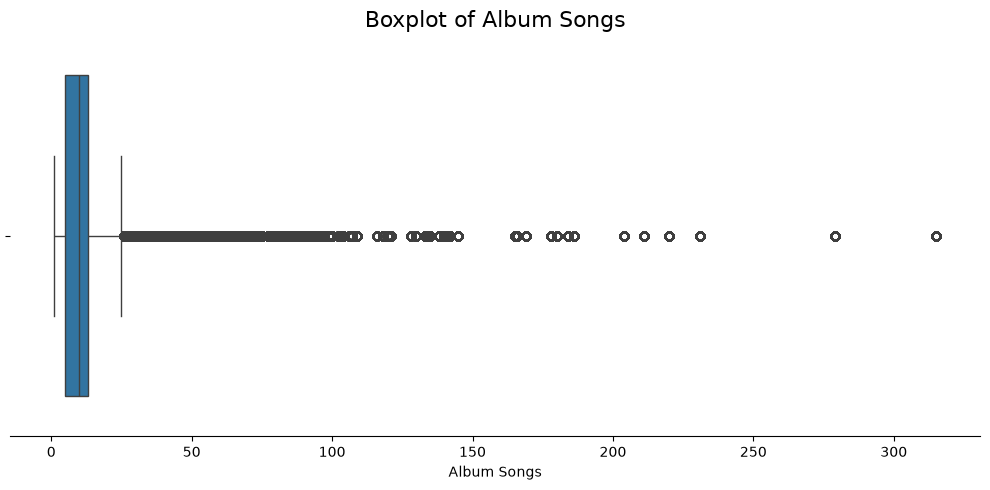

In [13]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['album_songs'])

plt.title("Boxplot of Album Songs", fontsize=16)
plt.xlabel("Album Songs")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

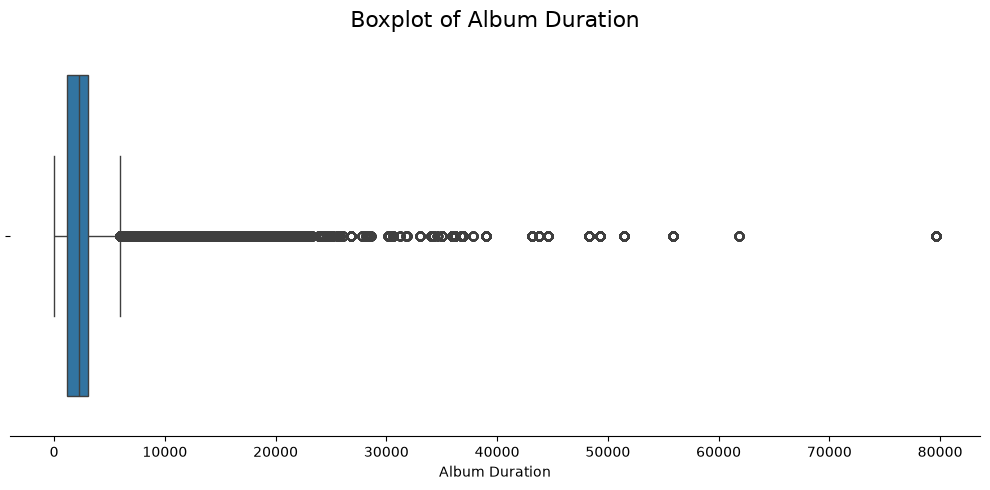

In [14]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['album_duration'])

plt.title("Boxplot of Album Duration", fontsize=16)
plt.xlabel("Album Duration")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

### 1.2.2 Feature Transformation

In [15]:
X = df.drop(columns='genre')
y = df['genre']

In [ ]:
def detect_outliers(ds: pd.Series):
    Q1 = ds.quantile(0.25)
    Q3 = ds.quantile(0.75)
    IQR = Q3 - Q1

    outliers = (
        (ds < Q1 - 1.5 * IQR) |
        (ds > Q3 + 1.5 * IQR)
    )

    return outliers

In [36]:
album_songs_outliers = detect_outliers(X['album_songs'])
print(f"{album_songs_outliers.sum():,} - potential outliers ({album_songs_outliers.mean():.2%})")

121,074 - potential outliers (5.73%)


In [38]:
album_duration_outliers = detect_outliers(X['album_duration'])
print(f"{album_duration_outliers.sum():,} - potential outliers ({album_duration_outliers.mean():.2%})")

105,243 - potential outliers (4.98%)


In [37]:
outlier_songs = X.loc[
    album_songs_outliers,
    ["track_name", "album_name", "album_songs"]
].sort_values("album_songs", ascending=False)

display(outlier_songs.head(10))
display(outlier_songs.tail(10))

,track_name,album_name,album_songs
44791,"Heinichen: Kleines harmonisches Labyrinth, BWV...",Bach: Complete Organ Works (Analogue Version -...,315
44774,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,315
44775,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,315
44776,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,315
44778,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,315
44779,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,315
44780,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,315
44781,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,315
44782,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,315
44784,"Vetter: ""Allein Gott in der Höh' sei Ehr'"" in ...",Bach: Complete Organ Works (Analogue Version -...,315


,track_name,album_name,album_songs
934056,"How Long, How Long Blues",Atomic Boogie,26
934055,Rock Of Gibraltar Blues,Atomic Boogie,26
934054,Howling Winds,Atomic Boogie,26
934053,Whistle Stop Blues,Atomic Boogie,26
934052,It's A Low Down Dirty Shame,Atomic Boogie,26
2111869,Ağla Ağla - Live,Söz & Müzik: Tan Taşçı (Live),26
2111868,Ziyan & Doğum Günü - Live,Söz & Müzik: Tan Taşçı (Live),26
2111867,Yalvarırım - Live,Söz & Müzik: Tan Taşçı (Live),26
140341,Born In a Trunk - Instrumental,"Very 'Eavy, Very 'Umble (Expanded Version)",26
140304,Dreammare - Alternative Version,"Very 'Eavy, Very 'Umble (Expanded Version)",26


To split our data we chose the strategy to have 80% as training data set, then a combination of a 10% validation set and a 10% test set.

In [39]:
groups = X['album_id']

In [40]:
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [41]:
train_idx, remaining_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

X_remaining = X.iloc[remaining_idx]
y_remaining = y.iloc[remaining_idx]

In [42]:
groups_remaining = groups.iloc[remaining_idx]

In [18]:
splitter_remaining = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

In [19]:
validation_idx, test_idx = next(
    splitter_remaining.split(
        X_remaining,
        y_remaining,
        groups=groups_remaining
    )
)

X_validation = X_remaining.iloc[validation_idx]
y_validation = y_remaining.iloc[validation_idx]

X_test = X_remaining.iloc[test_idx]
y_test = y_remaining.iloc[test_idx]

In [20]:
print(f"Train:      {len(X_train):,} ({len(X_train) / len(X):.1%})")
print(f"Validation: {len(X_validation):,} ({len(X_validation) / len(X):.1%})")
print(f"Test:       {len(X_test):,} ({len(X_test) / len(X):.1%})")

Train:      1,690,188 (80.0%)
Validation: 211,274 (10.0%)
Test:       211,274 (10.0%)


In [24]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(token_pattern=r"(?u)\b[^\W\d_]+\b")),
    ("clf", MultinomialNB())
])

In [105]:
parameters = {
    "tfidf__ngram_range": [(1, 1)],
    "tfidf__max_features": [1000],
    "tfidf__min_df": [2, 3, 5, 8, 10, 15],
    "tfidf__max_df": [0.5, 0.75],
}

In [ ]:
#X_tuning = np.concatenate([
#    X_train["track_name"].astype(str).to_numpy(),
#    X_validation["track_name"].astype(str).to_numpy()
#])

#X_tuning = np.concatenate([
#    X_train["album_name"].astype(str).to_numpy(),
#    X_validation["album_name"].astype(str).to_numpy()
#])

In [106]:
X_tuning = np.concatenate([
    X_train[["track_name", "album_name"]].agg(" ".join, axis=1).to_numpy(),
    X_validation[["track_name", "album_name"]].agg(" ".join, axis=1).to_numpy()
])

y_tuning = np.concatenate([
    y_train.to_numpy(),
    y_validation.to_numpy()
])

# -1 = training sample, 0 = validation sample
test_fold = np.concatenate([
    np.full(len(X_train), -1),
    np.zeros(len(X_validation), dtype=int)
])

validation_split = PredefinedSplit(test_fold)

In [107]:
grid_search = GridSearchCV(
    pipeline,
    parameters,
    cv=validation_split,
    scoring="f1_macro",
    verbose=2,
    n_jobs=10
)

In [108]:
grid_search.fit(X_tuning, y_tuning)

Fitting 1 folds for each of 12 candidates, totalling 12 fits
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=2, tfidf__ngram_range=(1, 1); total time=   9.8s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=3, tfidf__ngram_range=(1, 1); total time=   9.7s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=8, tfidf__ngram_range=(1, 1); total time=  10.4s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=10, tfidf__ngram_range=(1, 1); total time=  10.7s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=15, tfidf__ngram_range=(1, 1); total time=  10.8s
[CV] END tfidf__max_df=0.75, tfidf__max_features=1000, tfidf__min_df=2, tfidf__ngram_range=(1, 1); total time=  10.7s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=5, tfidf__ngram_range=(1, 1); total time=  13.3s
[CV] END tfidf__max_df=0.75, tfidf__max_features=1000, tfidf__min_df=3, tfidf__ngram_range=(1, 1); total time=  13.0s

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...inomialNB())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'tfidf__max_df': [0.5, 0.75], 'tfidf__max_features': [1000], 'tfidf__min_df': [2, 3, ...], 'tfidf__ngram_range': [(1, ...)]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",10
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","PredefinedSpl...e=(1901462,)))"
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricev

In [110]:
print("Best parameters:", grid_search.best_params_)
print("Best validation macro-F1:", grid_search.best_score_)

Best parameters: {'tfidf__max_df': 0.5, 'tfidf__max_features': 1000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
Best validation macro-F1: 0.12094277053799399


Using only track_name, with a vocabulary of size 1000 we got a macro-F1 of: 0.075
Using only album_name, we got a macro-F1 of: 0.113
Using a combination of track_name and album_name, in the format: `track_name album_name`, we get a macro-F1 of: 0.121

In [111]:
best_model = grid_search.best_estimator_

tfidf = best_model.named_steps["tfidf"]

vocabulary = tfidf.get_feature_names_out()

print(vocabulary[:100])

['a' 'about' 'acoustic' 'act' 'acústico' 'adagio' 'after' 'again' 'age'
 'ah' 'ain' 'air' 'al' 'album' 'alive' 'all' 'allegretto' 'allegro' 'alma'
 'alone' 'along' 'alright' 'alternate' 'always' 'am' 'amar' 'america'
 'american' 'amor' 'amour' 'an' 'and' 'andante' 'angel' 'angels'
 'anniversary' 'anos' 'another' 'anthem' 'anthology' 'ao' 'are' 'arena'
 'aria' 'arms' 'around' 'arr' 'art' 'as' 'asot' 'at' 'au' 'auf' 'aus'
 'away' 'años' 'b' 'baby' 'bach' 'back' 'bad' 'ballet' 'band' 'bang' 'bar'
 'bass' 'battle' 'be' 'beach' 'beat' 'beats' 'beautiful' 'beauty' 'been'
 'beethoven' 'before' 'behind' 'believe' 'bells' 'ben' 'best' 'better'
 'between' 'beyond' 'big' 'bir' 'bird' 'bizet' 'black' 'blind' 'blood'
 'blue' 'bluegrass' 'blues' 'body' 'bonus' 'boogie' 'book' 'boom' 'bop']


The next step in our pipeline is feature transformation. As discussed in [Feature Distribution and Class Imbalance](#114-feature-distribution-and-class-imbalance), some numerical features exhibit skewness.

To address this, we use the **Yeo–Johnson transformation**, a power transformation that can reduce skewness in numerical features. We chose this method because our dataset contains both positive and negative values, and Yeo–Johnson can also handle zero values. Unlike the Box–Cox transformation, which requires strictly positive values, Yeo–Johnson can be applied to a wider range of numerical data.

We enable standardization as part of the transformation so that the resulting features have a mean of approximately zero and a standard deviation of approximately one. The transformation is fitted on the training data only to prevent data leakage.

For more information, see [Skewness Be Gone: Transformative Tricks for Data Scientists](https://machinelearningmastery.com/skewness-be-gone-transformative-tricks-for-data-scientists/).

In [71]:
df.skew(numeric_only=True)

explicit            4.167158
genre               0.268191
acousticness        0.372811
danceability       -0.218410
energy             -0.324785
instrumentalness    1.193545
key                -0.001304
liveness            1.960641
loudness           -1.393415
mode               -0.685279
speechiness         4.772682
tempo               0.360188
time_signature     -3.139468
valence             0.047027
duration_seconds    8.492853
album_songs         8.132853
dtype: float64

In [21]:
continuous_features = [
    'acousticness',
    'danceability',
    'energy',
    'instrumentalness',
    'liveness',
    'loudness',
    'speechiness',
    'tempo',
    'valence',
    'duration_seconds'
]

categorical_features = [
    "key",
    "time_signature",
]

binary_features = [
    'mode',
    'explicit'
]

skewed_features = [
    'instrumentalness',
    'liveness',
    'loudness',
    'speechiness',
    'duration_seconds',
    'album_songs'
]

In [22]:
non_skewed_features = [
    feature for feature in continuous_features
    if feature not in skewed_features
]

In [23]:
ss = StandardScaler().set_output(transform='pandas')
ohe = OneHotEncoder(sparse_output=False).set_output(transform='pandas')
pt = PowerTransformer(method='yeo-johnson', standardize=True).set_output(transform='pandas')
tiv = TfidfVectorizer(
    token_pattern=r"(?u)\b[^\W\d_]+\b", 
    min_df=2, 
    max_df=0.5, 
    ngram_range=(1, 1),
    max_features=1000
)

In [24]:
X_train_skewed = pt.fit_transform(
    X_train[skewed_features]
)

X_validation_skewed = pt.transform(
    X_validation[skewed_features]
)

X_test_skewed = pt.transform(
    X_test[skewed_features]
)

In [25]:
X_train_non_skewed = ss.fit_transform(
    X_train[non_skewed_features]
)

X_validation_non_skewed = ss.transform(
    X_validation[non_skewed_features]
)

X_test_non_skewed = ss.transform(
    X_test[non_skewed_features]
)

In [26]:
X_train_cat = ohe.fit_transform(X_train[categorical_features])
X_validation_cat = ohe.transform(X_validation[categorical_features])
X_test_cat = ohe.transform(X_test[categorical_features])

In [27]:
X_train_text = tiv.fit_transform(
    X_train["track_name"] + " " + 
    X_train["album_name"]
)

X_validation_text = tiv.transform(
    X_validation["track_name"] + " " +
    X_validation["album_name"]
)

X_test_text = tiv.transform(
    X_test["track_name"] + " " +
    X_test["album_name"]
)

In [28]:
X_train_numeric_cat = pd.concat([X_train_skewed, X_train_non_skewed, X_train_cat], axis=1)
X_test_numeric_cat = pd.concat([X_test_skewed, X_test_non_skewed, X_test_cat], axis=1)
X_validation_numeric_cat = pd.concat([X_validation_skewed, X_validation_non_skewed, X_validation_cat], axis=1)

In [38]:
X_train_transformed = hstack(
    [csr_matrix(X_train_numeric_cat), X_train_text], format="csr"
)
X_validation_transformed = hstack(
    [csr_matrix(X_validation_numeric_cat), X_validation_text], format="csr"
)
X_test_transformed = hstack(
    [csr_matrix(X_test_numeric_cat), X_test_text], format="csr"
)

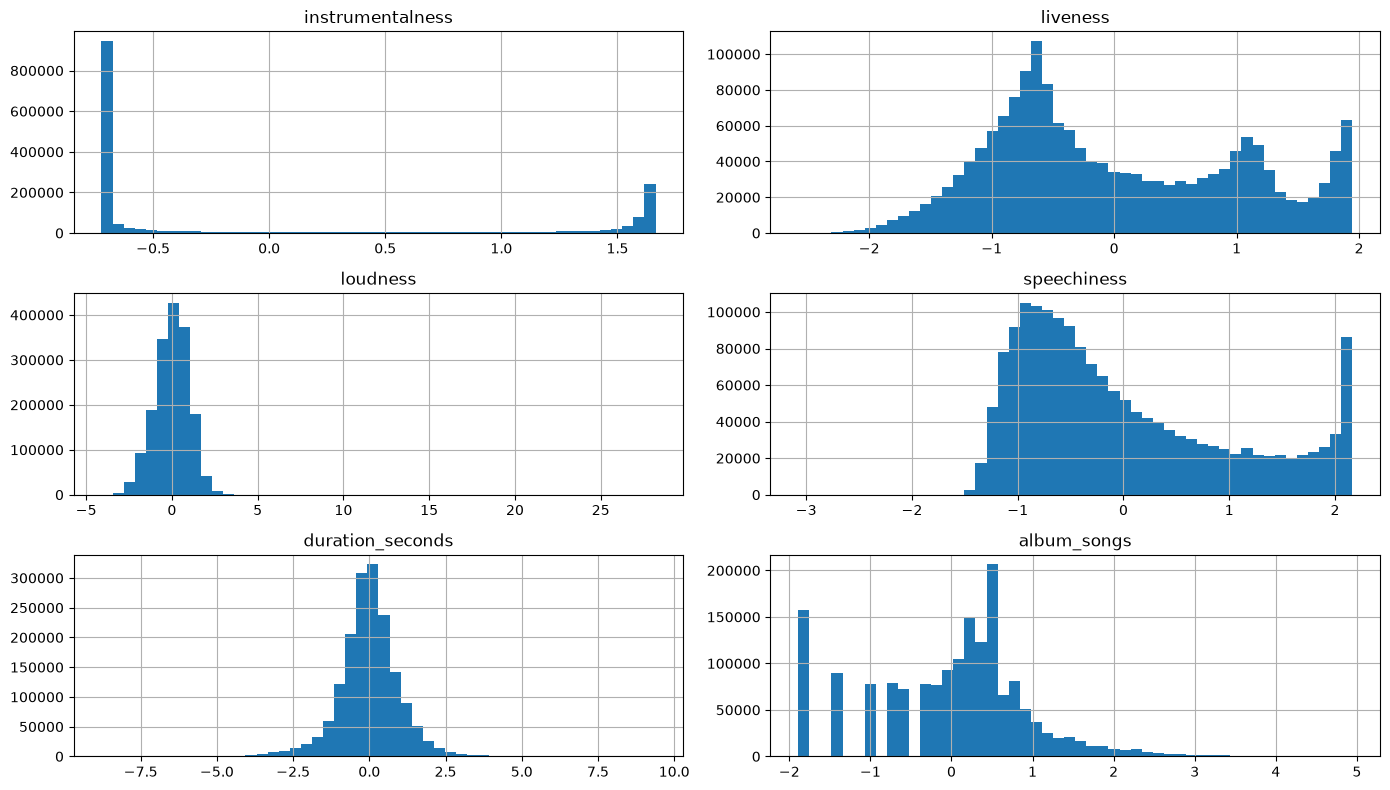

In [122]:
X_train_numeric_cat[skewed_features].hist(bins=50, figsize=(14, 8))

plt.tight_layout()
plt.show()

In [123]:
X_train_numeric_cat.skew(numeric_only=True)

instrumentalness      0.837662
liveness              0.365526
loudness              0.051703
speechiness           0.791418
duration_seconds      0.063618
album_songs           0.009105
acousticness          0.374148
danceability         -0.218924
energy               -0.325624
tempo                 0.359691
valence               0.046963
key_0                 2.325850
key_1                 3.068984
key_2                 2.433958
key_3                 5.289150
key_4                 3.062224
key_5                 2.970037
key_6                 3.823170
key_7                 2.229553
key_8                 3.877729
key_9                 2.504168
key_10                3.553005
key_11                3.329932
time_signature_0    183.849993
time_signature_1      9.028693
time_signature_3      2.485167
time_signature_4     -2.052095
time_signature_5      6.932422
dtype: float64

In [36]:
pca = PCA().set_output(transform='pandas')

In [39]:
X_train_pca = pca.fit_transform(X_train_transformed)
X_validation_pca = pca.transform(X_validation_transformed)
X_test_pca = pca.transform(X_test_transformed)

In [41]:
print("Training samples:", X_train_pca.shape[0])
print("PCA dimensions:", X_train_pca.shape[1])

memory_gb = X_train_pca.memory_usage(index=True, deep=True).sum() / 1e9
print(f"DataFrame memory usage: {memory_gb:.2f} GB")

Training samples: 1690188
PCA dimensions: 1027
DataFrame memory usage: 13.89 GB


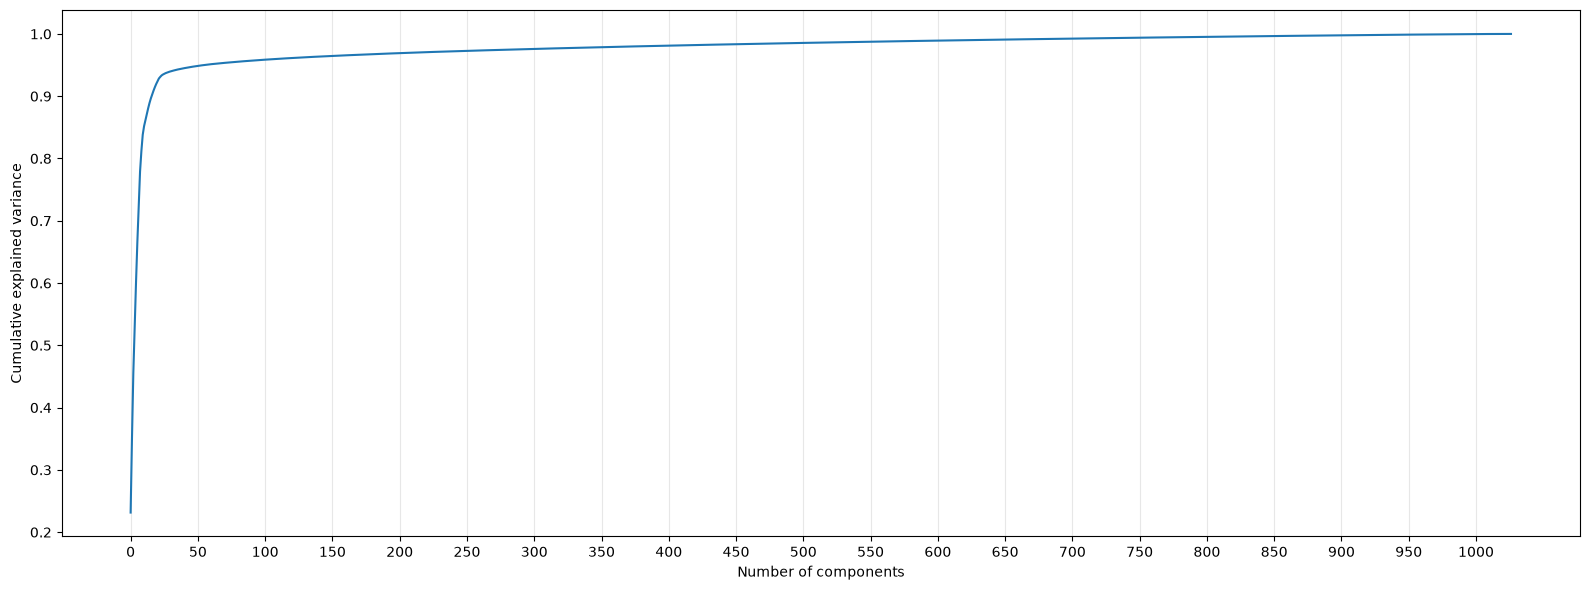

In [36]:
plt.figure(figsize=(16, 6))

plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xticks(np.arange(0, len(pca.explained_variance_ratio_) + 1, 50))
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
X_train_pca.head()

,pca0,pca1,pca2,pca3,pca4,pca5,pca6,pca7,pca8,pca9,pca10,pca11,pca12,pca13,pca14,pca15,pca16,pca17,pca18,pca19,pca20,pca21,pca22,pca23,pca24,pca25,pca26,pca27,pca28,pca29,pca30,pca31,pca32,pca33,pca34,pca35,pca36,pca37,pca38,pca39,pca40,pca41,pca42,pca43,pca44,pca45,pca46,pca47,pca48,pca49,pca50,pca51,pca52,pca53,pca54,pca55,pca56,pca57,pca58,pca59,pca60,pca61,pca62,pca63,pca64,pca65,pca66,pca67,pca68,pca69,pca70,pca71,pca72,pca73,pca74,pca75,pca76,pca77,pca78,pca79,pca80,pca81,pca82,pca83,pca84,pca85,pca86,pca87,pca88,pca89,pca90,pca91,pca92,pca93,pca94,pca95,pca96,pca97,pca98,pca99,pca100,pca101,pca102,pca103,pca104,pca105,pca106,pca107,pca108,pca109,pca110,pca111,pca112,pca113,pca114,pca115,pca116,pca117,pca118,pca119,pca120,pca121,pca122,pca123,pca124,pca125,pca126,pca127,pca128,pca129,pca130,pca131,pca132,pca133,pca134,pca135,pca136,pca137,pca138,pca139,pca140,pca141,pca142,pca143,pca144,pca145,pca146,pca147,pca148,pca149,pca150,pca151,pca152,pca153,pca154,pca155,pca156,pca157,pca158,pca159,pca160,pca161,pca162,pca163,pca164,pca165,pca166,pca167,pca168,pca169,pca170,pca171,pca172,pca173,pca174,pca175,pca176,pca177,pca178,pca179,pca180,pca181,pca182,pca183,pca184,pca185,pca186,pca187,pca188,pca189,pca190,pca191,pca192,pca193,pca194,pca195,pca196,pca197,pca198,pca199,pca200,pca201,pca202,pca203,pca204,pca205,pca206,pca207,pca208,pca209,pca210,pca211,pca212,pca213,pca214,pca215,pca216,pca217,pca218,pca219,pca220,pca221,pca222,pca223,pca224,pca225,pca226,pca227,pca228,pca229,pca230,pca231,pca232,pca233,pca234,pca235,pca236,pca237,pca238,pca239,pca240,pca241,pca242,pca243,pca244,pca245,pca246,pca247,pca248,pca249,pca250,pca251,pca252,pca253,pca254,pca255,pca256,pca257,pca258,pca259,pca260,pca261,pca262,pca263,pca264,pca265,pca266,pca267,pca268,pca269,pca270,pca271,pca272,pca273,pca274,pca275,pca276,pca277,pca278,pca279,pca280,pca281,pca282,pca283,pca284,pca285,pca286,pca287,pca288,pca289,pca290,pca291,pca292,pca293,pca294,pca295,pca296,pca297,pca298,pca299,pca300,pca301,pca302,pca303,pca304,pca305,pca306,pca307,pca308,pca309,pca310,pca311,pca312,pca313,pca314,pca315,pca316,pca317,pca318,pca319,pca320,pca321,pca322,pca323,pca324,pca325,pca326,pca327,pca328,pca329,pca330,pca331,pca332,pca333,pca334,pca335,pca336,pca337,pca338,pca339,pca340,pca341,pca342,pca343,pca344,pca345,pca346,pca347,pca348,pca349,pca350,pca351,pca352,pca353,pca354,pca355,pca356,pca357,pca358,pca359,pca360,pca361,pca362,pca363,pca364,pca365,pca366,pca367,pca368,pca369,pca370,pca371,pca372,pca373,pca374,pca375,pca376,pca377,pca378,pca379,pca380,pca381,pca382,pca383,pca384,pca385,pca386,pca387,pca388,pca389,pca390,pca391,pca392,pca393,pca394,pca395,pca396,pca397,pca398,pca399,pca400,pca401,pca402,pca403,pca404,pca405,pca406,pca407,pca408,pca409,pca410,pca411,pca412,pca413,pca414,pca415,pca416,pca417,pca418,pca419,pca420,pca421,pca422,pca423,pca424,pca425,pca426,pca427,pca428,pca429,pca430,pca431,pca432,pca433,pca434,pca435,pca436,pca437,pca438,pca439,pca440,pca441,pca442,pca443,pca444,pca445,pca446,pca447,pca448,pca449,pca450,pca451,pca452,pca453,pca454,pca455,pca456,pca457,pca458,pca459,pca460,pca461,pca462,pca463,pca464,pca465,pca466,pca467,pca468,pca469,pca470,pca471,pca472,pca473,pca474,pca475,pca476,pca477,pca478,pca479,pca480,pca481,pca482,pca483,pca484,pca485,pca486,pca487,pca488,pca489,pca490,pca491,pca492,pca493,pca494,pca495,pca496,pca497,pca498,pca499,pca500,pca501,pca502,pca503,pca504,pca505,pca506,pca507,pca508,pca509,pca510,pca511,pca512,pca513,pca514,pca515,pca516,pca517,pca518,pca519,pca520,pca521,pca522,pca523,pca524,pca525,pca526,pca527,pca528,pca529,pca530,pca531,pca532,pca533,pca534,pca535,pca536,pca537,pca538,pca539,pca540,pca541,pca542,pca543,pca544,pca545,pca546,pca547,pca548,pca549,pca550,pca551,pca552,pca553,pca554,pca555,pca556,pca557,pca558,pca559,pca560,pca561,pca562,pca563,pca564,pca565,pca566,pca567,pca568,pca569,pca570,pca571,pca572,pca573,pca574,pca575,pca576,pca577,pca578,pca579,pca580,pca581,pca582,pca583,pca584,pca585,pca586,

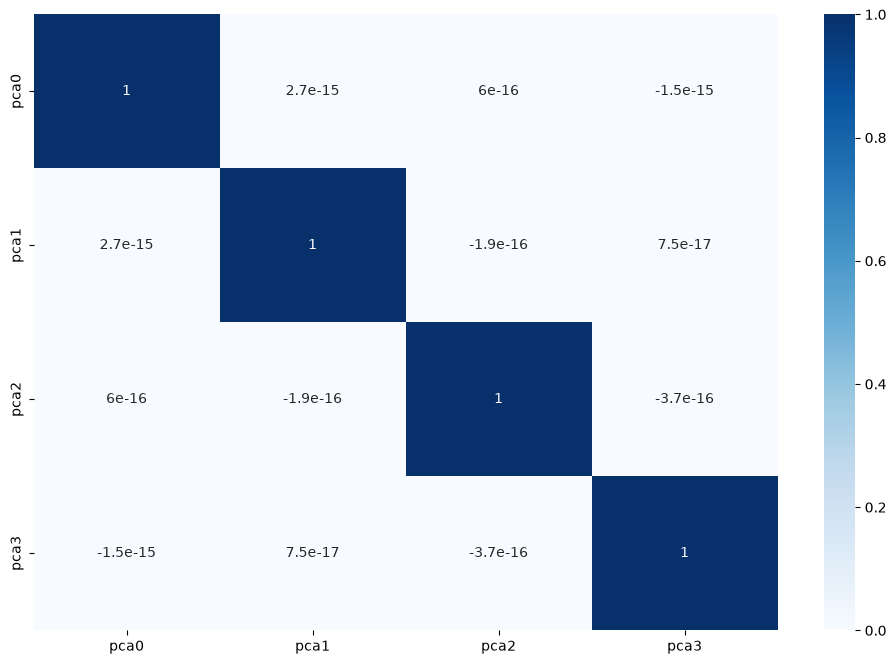

In [38]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    X_train_pca[['pca0', 'pca1', 'pca2', 'pca3']].corr(),
    annot=True,
    cmap='Blues'
)

plt.show()

We use a sparse method here, to save RAM.

In [43]:
svd = TruncatedSVD(n_components=30, random_state=42)

In [44]:
X_train_svd = svd.fit_transform(X_train_transformed)
X_validation_svd = svd.transform(X_validation_transformed)
X_test_svd = svd.transform(X_test_transformed)

## 2.1 Model training

In [41]:
lr_model = LogisticRegression(
        solver="saga",
        max_iter=300
)

lr_model.fit(X_train_svd, y_train)

/home/thomas/projects/venv/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",300
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of t

## 2.2 Model evaluation

In [46]:
from sklearn.metrics import f1_score

y_pred = cb_model.predict(X_test_svd)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Model Accuracy: {accuracy:.2f}")
print(f"Test Macro-F1: {macro_f1:.4f}")

Model Accuracy: 0.23
Test Macro-F1: 0.1775
